# 01 · Modular addition: grokking과 attention 해부

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HisameOgasahara/tmp_llm_dit/blob/main/notebooks/01_modadd.ipynb)

`[a, b, =]`를 보고 `(a + b) mod 113`을 맞히는 태스크입니다. 전체 12,769개 조합 중 일부만 학습에 씁니다.

**grokking이란**
1. 학습 데이터는 금방 100% 맞힙니다(외우기). 이때 테스트 정확도는 낮습니다.
2. 한참 동안 아무 일도 없는 것처럼 보이다가, 어느 순간 **테스트 정확도가 갑자기 100%로** 뜁니다(일반화).
3. 그 시점에 숫자 임베딩이 **소수의 푸리에 주파수로 정리**됩니다. 덧셈을 원 위의 회전으로 계산하는 알고리즘을 찾았다는 신호입니다.

**이전 실행에서 알게 된 것**: 표준 GPT-2와 Llama(LayerNorm + 임베딩 공유)는 외우자마자 바로 일반화해서 grokking 지연이 없었습니다.
grokking이 잘 알려진 원 실험(Nanda et al. 2023)은 **LayerNorm이 없고 출력층이 분리된** 모델을 씁니다. 그래서 이번엔 두 부품을 하나씩 꺼 봅니다.

| 그룹 | 실행 | 바꾼 것 |
|---|---|---|
| A. 구조 비교 | GPT-2 / Llama / Llama wd=0 | 아키텍처, weight decay |
| B. grokking ablation | GPT-2 -LN / GPT-2 -tie / GPT-2 -LN -tie (원 논문) / 원 논문 30%→20% | LayerNorm, 임베딩 공유, 학습 데이터 비율 |
| C. 긴 학습 | 원 논문 설정을 10만 step, 학습률 1e-3 / 3e-4 | grokking 도약까지 가는가 |

**두 번째 실행에서 알게 된 것**
- 지연을 없앤 주범은 **LayerNorm**. 빼면 외운 채 정체하는 구간이 생기지만, 3만 step으로는 일반화 도약까지 못 감 → C에서 길게 학습
- Llama는 모든 입력에서 attention이 정확히 균등(1/3) → attention을 안 쓰고 푼 것으로 보임 → 6번에서 **attention을 강제로 바꿔 보는 인과 검사**

1층, d_model 128, head 4개. T4 기준 A+B 약 20분, C 약 30분입니다. 위쪽 `RUN_MAIN`, `RUN_LONG`으로 나눠 실행할 수 있습니다.

## 0. 환경 준비

In [1]:
import os
REPO_DIR = "/content/tmp_llm_dit"
if not os.path.exists(REPO_DIR):
    !git clone -q https://github.com/HisameOgasahara/tmp_llm_dit.git {REPO_DIR}
else:
    !git -C {REPO_DIR} pull -q
%cd {REPO_DIR}
!pip -q install -U -r requirements-colab.txt
# Colab 기본 torchao 가 최신 diffusers 와 버전이 안 맞아 import 가 깨짐 → 쓰지 않으므로 제거
!pip -q uninstall -y torchao

/content/tmp_llm_dit
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 70.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 68.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 65.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 75.7 MB/s eta 0:00:00


In [2]:
import sys, torch
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음 (런타임 유형을 GPU로 바꾸세요)")
!git log -1 --format='repo commit: %h %s'

torch 2.11.0+cu130 | GPU: Tesla T4
repo commit: af92f04 Merge Colab run outputs (kept regenerated notebooks)


## 1. 설정

In [3]:
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 그래프 한글 폰트
plt.rcParams["axes.unicode_minus"] = False
import pandas as pd
import torch
from miniarch.train import seed_all, get_device, count_params
from miniarch.tasks import modadd
from miniarch.analysis.fourier import freq_energy, fourier_2d

PREFIX = "01_modadd"
dev = get_device()
P, STEPS = 113, 30000                 # 빨리 훑어보려면 STEPS 를 줄이세요
D_MODEL, N_HEAD, N_LAYER = 128, 4, 1
RUN_MAIN = True                       # A, B 그룹 (약 20분)
RUN_LONG = True                       # C 그룹: 10만 step 긴 학습 (약 30분)
STEPS_LONG = 100000

RUNS = {
    # 이름: 구조, weight decay, LayerNorm, 임베딩 공유, 학습 데이터 비율, 그룹
    "GPT-2":              dict(kind="gpt2",  wd=1.0, ln=True,  tie=True,  frac=0.3, group="A"),
    "Llama":              dict(kind="llama", wd=1.0, ln=True,  tie=True,  frac=0.3, group="A"),
    "Llama, wd=0":        dict(kind="llama", wd=0.0, ln=True,  tie=True,  frac=0.3, group="A"),
    "GPT-2 -LN":          dict(kind="gpt2",  wd=1.0, ln=False, tie=True,  frac=0.3, group="B"),
    "GPT-2 -tie":         dict(kind="gpt2",  wd=1.0, ln=True,  tie=False, frac=0.3, group="B"),
    "GPT-2 -LN -tie":     dict(kind="gpt2",  wd=1.0, ln=False, tie=False, frac=0.3, group="B"),
    "GPT-2 -LN -tie 20%": dict(kind="gpt2",  wd=1.0, ln=False, tie=False, frac=0.2, group="B"),
}
LONG_RUNS = {
    "원논문 30% lr1e-3 (long)": dict(kind="gpt2", wd=1.0, ln=False, tie=False, frac=0.3, lr=1e-3),
    "원논문 30% lr3e-4 (long)": dict(kind="gpt2", wd=1.0, ln=False, tie=False, frac=0.3, lr=3e-4),
    "원논문 20% lr3e-4 (long)": dict(kind="gpt2", wd=1.0, ln=False, tie=False, frac=0.2, lr=3e-4),
}
COLORS = dict(zip(list(RUNS) + list(LONG_RUNS), ["tab:blue", "tab:orange", "tab:gray", "tab:green", "tab:purple",
                                                 "tab:red", "tab:brown", "darkred", "crimson", "sienna"]))
datasets = {f: modadd.make_data(P, f, seed=0, device=dev) for f in {0.2, 0.3}}
for f, d in sorted(datasets.items()):
    print(f"학습 비율 {f:.0%}: 학습 {len(d.train_y):,}개 / 테스트 {len(d.test_y):,}개")

학습 비율 20%: 학습 2,553개 / 테스트 10,216개
학습 비율 30%: 학습 3,830개 / 테스트 8,939개


## 2. 학습

진행 표시줄의 `train`/`test`는 정확도, `wn`은 전체 가중치 크기입니다.

In [4]:
models, hists = {}, {}
for name, c in (RUNS.items() if RUN_MAIN else []):
    seed_all(0)
    m = modadd.build_model(c["kind"], P, D_MODEL, N_HEAD, N_LAYER, use_ln=c["ln"], tie=c["tie"]).to(dev)
    print(f"\n▶ {name}  params={count_params(m):,}")
    hists[name] = modadd.train(m, datasets[c["frac"]], steps=STEPS, wd=c["wd"])
    models[name] = m

def summarize():
    return pd.DataFrame({n: {"외우기 (train>99%)": h["memorize_step"], "일반화 (test>99%)": h["grok_step"],
                            "지연 (step)": (h["grok_step"] - h["memorize_step"]) if h["grok_step"] else None,
                            "최종 test": round(h["test_acc"][-1], 4), "최종 가중치 크기": round(h["weight_norm"][-1], 1),
                            "상위5 주파수 비율": round(h["fourier_top5"][-1], 3)} for n, h in hists.items()}).T
summary = summarize()
summary


▶ GPT-2  params=213,504


  0%|          | 0/30001 [00:00<?, ?it/s]


▶ Llama  params=277,120


  0%|          | 0/30001 [00:00<?, ?it/s]


▶ Llama, wd=0  params=277,120


...


▶ GPT-2 -LN -tie  params=227,328


  0%|          | 0/30001 [00:00<?, ?it/s]


▶ GPT-2 -LN -tie 20%  params=227,328


  0%|          | 0/30001 [00:00<?, ?it/s]

,외우기 (train>99%),일반화 (test>99%),지연 (step),최종 test,최종 가중치 크기,상위5 주파수 비율
GPT-2,100.0,600.0,500.0,1.0000,23.8,0.581
Llama,100.0,600.0,500.0,0.9974,39.6,0.299
"Llama, wd=0",100.0,2800.0,2700.0,0.9862,551.6,0.245
GPT-2 -LN,NaN,NaN,NaN,0.6891,53.5,0.602
GPT-2 -tie,100.0,900.0,800.0,1.0000,27.4,0.650
GPT-2 -LN -tie,5100.0,NaN,NaN,0.8972,38.6,0.800
GPT-2 -LN -tie 20%,4400.0,NaN,NaN,0.1620,51.0,0.331


## 3. 학습 곡선

- **왼쪽**: 점선이 학습, 실선이 테스트 정확도입니다. 두 선 사이 간격이 "외웠지만 아직 일반화 못 한" 구간, 즉 grokking 지연입니다.
- **가운데**: 가중치 크기. weight decay는 외운 뒤에도 가중치를 계속 줄여서 더 단순한(일반화되는) 해법 쪽으로 밉니다.
- **오른쪽**: 임베딩 에너지 중 상위 5개 주파수 비율. 올라가면 푸리에 해법으로 정리되고 있다는 뜻입니다.
- 세로 점선은 각 실행의 일반화 시점입니다.

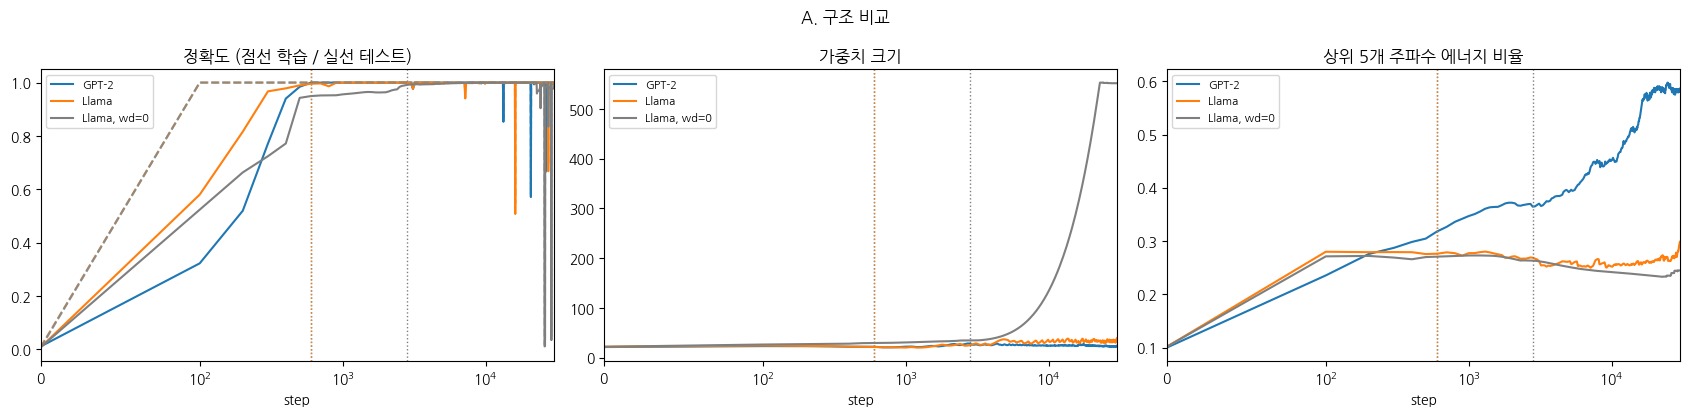

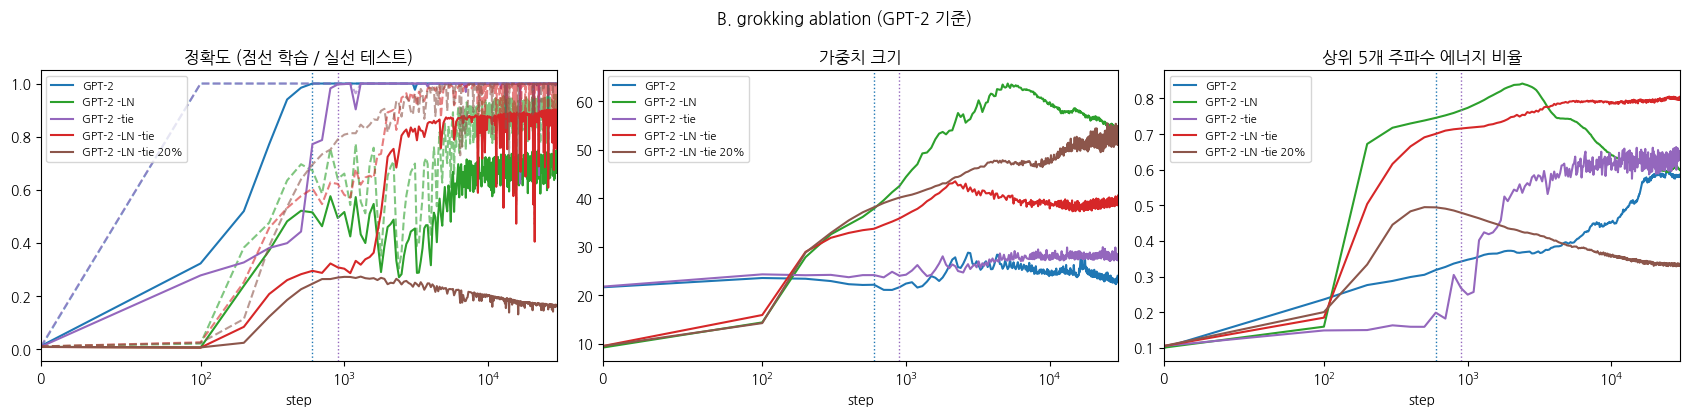

In [5]:
def plot_curves(names, title, xmax=STEPS):
    names = [n for n in names if n in hists]
    if not names:
        return None
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
    for name in names:
        h, c = hists[name], COLORS[name]
        axes[0].plot(h["step"], h["train_acc"], "--", color=c, alpha=0.6)
        axes[0].plot(h["step"], h["test_acc"], "-", color=c, label=name)
        axes[1].plot(h["step"], h["weight_norm"], color=c, label=name)
        axes[2].plot(h["step"], h["fourier_top5"], color=c, label=name)
        if h["grok_step"]:
            for ax in axes:
                ax.axvline(h["grok_step"], color=c, ls=":", lw=1)
    for ax, t in zip(axes, ["정확도 (점선 학습 / 실선 테스트)", "가중치 크기", "상위 5개 주파수 에너지 비율"]):
        ax.set_xscale("symlog", linthresh=100); ax.set_xlim(0, xmax)
        ax.set_title(t); ax.set_xlabel("step"); ax.legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout(); plt.show()
    return fig

fig_curves_A = plot_curves([n for n, c in RUNS.items() if c["group"] == "A"], "A. 구조 비교")
fig_curves_B = plot_curves(["GPT-2"] + [n for n, c in RUNS.items() if c["group"] == "B"], "B. grokking ablation (GPT-2 기준)")

## 4. 임베딩의 푸리에 스펙트럼

숫자 0~112의 임베딩을 주파수별로 분해한 결과입니다.
- 뾰족한 막대 몇 개 = 모델이 고른 "핵심 주파수". 깔끔한 푸리에 해법입니다.
- 넓게 퍼져 있으면 정답은 맞혀도 해법이 덜 정리된 상태입니다.
- 실행마다 **다른 주파수**를 고르는지도 보세요.

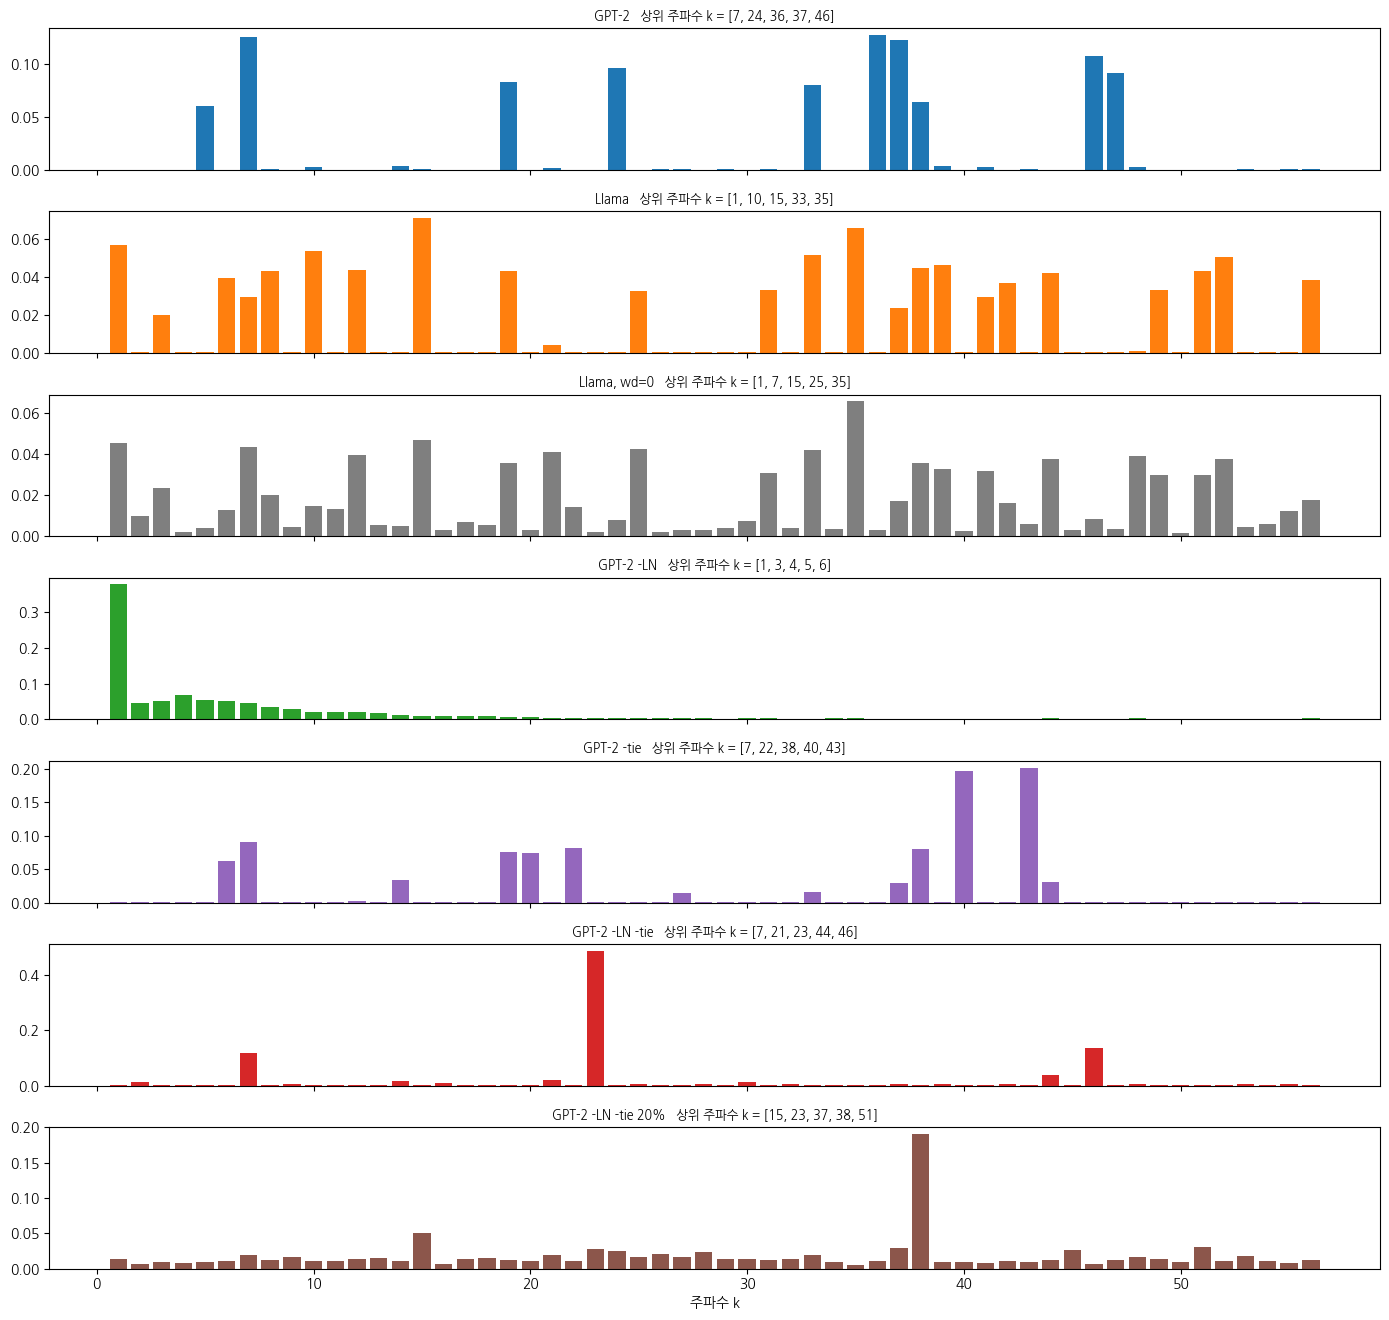

In [6]:
def plot_fourier(names):
    names = [n for n in names if n in models]
    if not names:
        return None
    fig, axes = plt.subplots(len(names), 1, figsize=(14, 1.9 * len(names)), sharex=True, squeeze=False)
    for ax, name in zip(axes[:, 0], names):
        e = freq_energy(modadd.embedding_weight(models[name]).detach(), P).cpu()
        e = e / e.sum()
        ax.bar(range(1, len(e) + 1), e, color=COLORS[name])
        ax.set_title(f"{name}   상위 주파수 k = {sorted((e.topk(5).indices + 1).tolist())}", fontsize=9)
    axes[-1, 0].set_xlabel("주파수 k")
    fig.tight_layout(); plt.show()
    return fig

fig_fourier = plot_fourier(list(RUNS))

## 5. Attention: `=`가 `a`를 얼마나 보는가, 모든 (a, b)에 대해

이전 실행의 평균 attention map은 a와 b를 반반 본다는 것만 보여줬습니다. 평균을 내면 패턴이 지워지기 때문입니다.
그래서 이번엔 **모든 113×113 입력**에 대해 `=` 위치가 `a`에 주는 attention 확률을 격자로 그립니다(행 = a, 열 = b, 나머지는 b와 `=`가 나눠 가짐).

- **윗줄**: head별 격자. 줄무늬나 격자무늬가 보이면 attention이 숫자 값에 따라 **주기적으로** 바뀐다는 뜻입니다. 원 논문에서는 이런 주기 패턴이 나옵니다.
- **아랫줄**: 그 격자의 2D 푸리에 크기. 밝은 점이 (a 방향 주파수, b 방향 주파수)입니다. 4번에서 찾은 임베딩 핵심 주파수와 같은 위치에 점이 찍히는지 비교해 보세요.

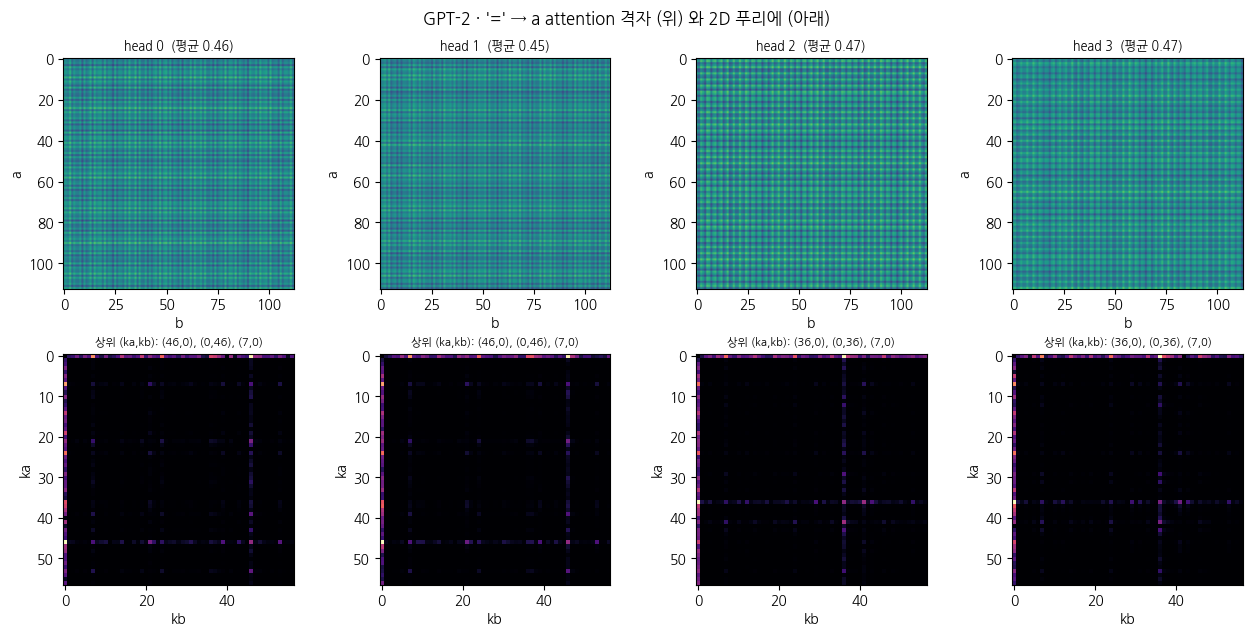

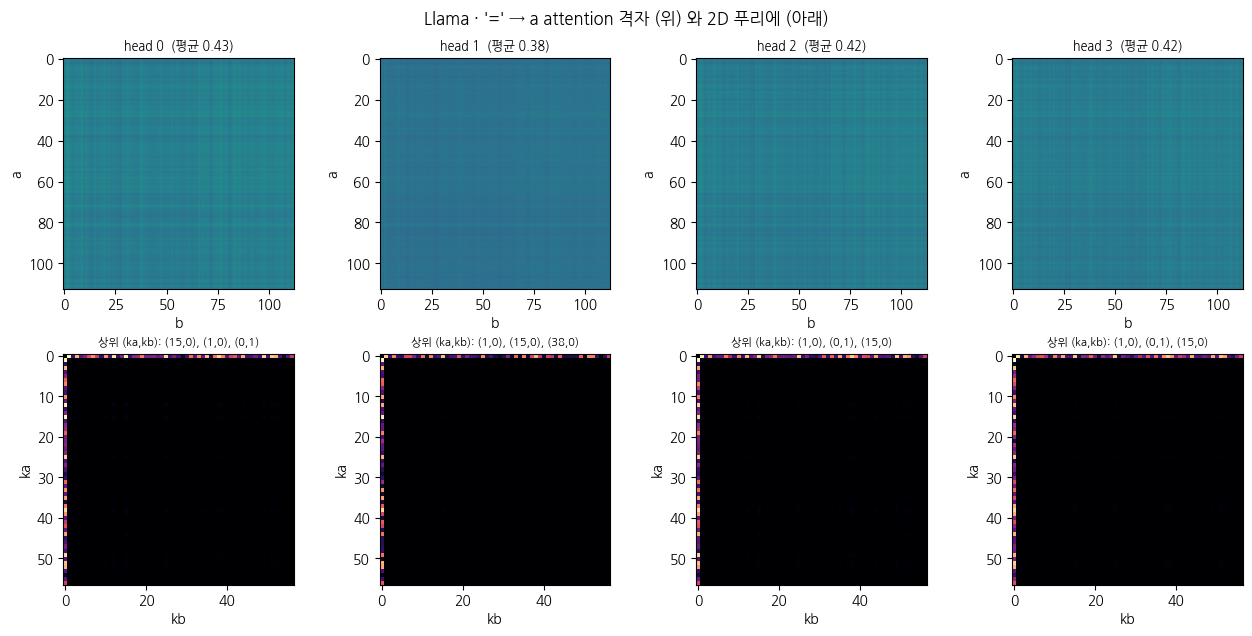

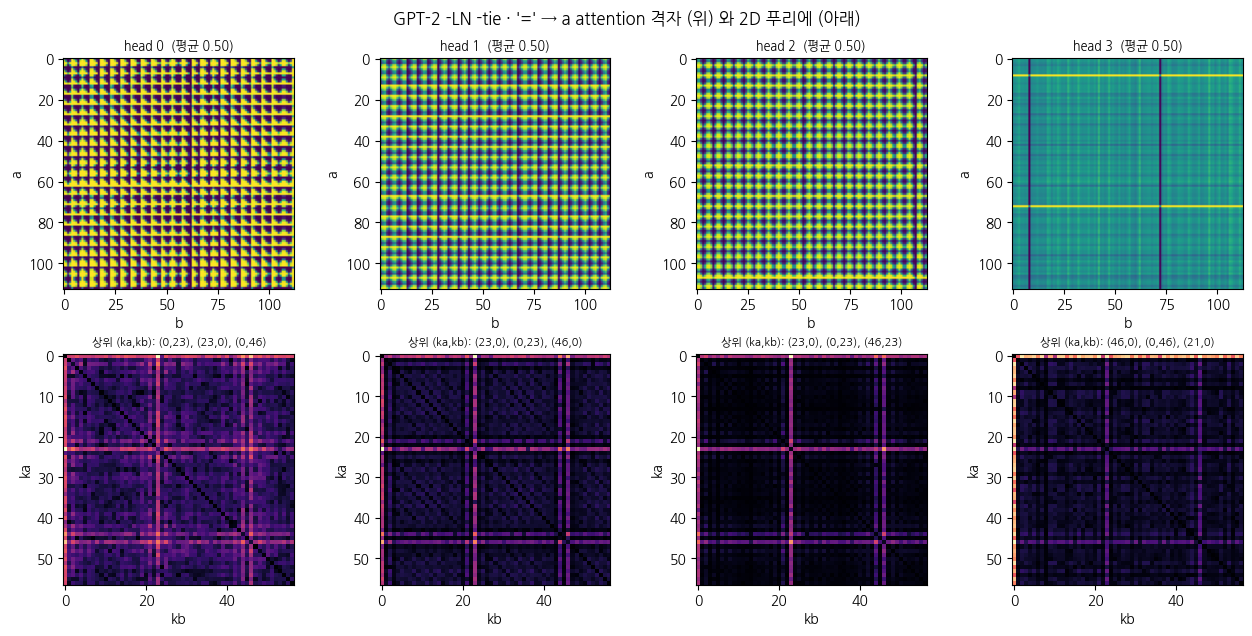

In [7]:
def plot_grid(name):
    G = modadd.attention_grid(models[name], P).cpu()          # [H, p, p]
    H = G.shape[0]
    fig, axes = plt.subplots(2, H, figsize=(3.2 * H, 6.4))
    for h in range(H):
        im = axes[0, h].imshow(G[h], cmap="viridis", vmin=0, vmax=1)
        axes[0, h].set_title(f"head {h}  (평균 {G[h].mean():.2f})", fontsize=9)
        axes[0, h].set_xlabel("b"); axes[0, h].set_ylabel("a")
        F = fourier_2d(G[h])
        axes[1, h].imshow(F.log1p(), cmap="magma")
        top = torch.topk(F.flatten(), 3).indices
        axes[1, h].set_title("상위 (ka,kb): " + ", ".join(f"({i // F.shape[1]},{i % F.shape[1]})" for i in top.tolist()), fontsize=8)
        axes[1, h].set_xlabel("kb"); axes[1, h].set_ylabel("ka")
    fig.suptitle(f"{name} · '=' → a attention 격자 (위) 와 2D 푸리에 (아래)"); fig.tight_layout(); plt.show()
    return fig

grid_figs = {n: plot_grid(n) for n in ["GPT-2", "Llama", "GPT-2 -LN -tie"] if n in models}

## 6. 인과 검사: attention을 바꿔치기하면 정답률이 떨어지는가

attention map이 "의미 있어 보이는 것"과 "실제로 계산에 쓰이는 것"은 다릅니다. 그래서 학습된 모델의 attention을 강제로 바꾸고 테스트 정확도를 다시 잽니다.
- **전부 균등**: 모든 head의 attention을 볼 수 있는 위치에 균등하게(`=` 위치면 a, b, `=` 각 1/3) 바꿉니다.
- **head 하나씩 평균 대체** (mean ablation): 해당 head만 테스트 전체의 평균 attention 패턴으로 고정합니다. 입력에 따라 달라지는 정보가 사라집니다.
- **|W_Q|, |W_K|**: Q, K 투영 가중치 크기. 0에 가까우면 attention 점수가 입력과 무관해집니다.

**읽는 법**: 바꿔도 정확도가 그대로면 그 attention은 계산에 쓰이지 않는 것입니다. 크게 떨어지면 그 head가 실제로 일을 하는 것입니다.
Llama는 정확도가 그대로이고, 체크무늬가 뚜렷했던 GPT-2 -LN -tie는 무너질 것으로 예상합니다.

In [8]:
rows = {}
for name, m in models.items():
    d = datasets[(RUNS | LONG_RUNS)[name]["frac"]]
    rows[name] = {**modadd.qk_norms(m), **modadd.attention_interventions(m, d)}
interv = pd.DataFrame(rows).T.round(3)
interv.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1, subset=[c for c in interv.columns if not c.startswith("|")])

,|W_Q|,|W_K|,원래,전부 균등,head0 평균대체,head1 평균대체,head2 평균대체,head3 평균대체
GPT-2,9.630000,6.897000,1.000000,0.303000,1.000000,1.000000,1.000000,1.000000
Llama,8.692000,8.442000,0.997000,0.991000,0.997000,0.997000,0.997000,0.997000
"Llama, wd=0",3.086000,3.437000,0.986000,0.017000,0.986000,0.987000,0.986000,0.986000
GPT-2 -LN,25.130000,5.582000,0.689000,0.008000,0.183000,0.105000,0.080000,0.095000
GPT-2 -tie,9.767000,7.048000,1.000000,0.352000,0.999000,0.998000,1.000000,1.000000
GPT-2 -LN -tie,13.311000,4.820000,0.897000,0.009000,0.214000,0.396000,0.180000,0.855000
GPT-2 -LN -tie 20%,29.434000,6.000000,0.162000,0.009000,0.088000,0.083000,0.075000,0.054000


## 7. 긴 학습: grokking 도약까지

LayerNorm 없는 원 논문 설정을 10만 step 학습합니다. 학습률 1e-3은 이전 실행에서 곡선이 심하게 출렁였기 때문에 3e-4도 같이 봅니다.
기대하는 모습: **학습 100% 이후 테스트가 낮게 머물다가 어느 순간 급상승**, 동시에 주파수 집중도 상승, 가중치 크기 감소.

In [9]:
for name, c in (LONG_RUNS.items() if RUN_LONG else []):
    seed_all(0)
    m = modadd.build_model(c["kind"], P, D_MODEL, N_HEAD, N_LAYER, use_ln=c["ln"], tie=c["tie"]).to(dev)
    print(f"
▶ {name}")
    hists[name] = modadd.train(m, datasets[c["frac"]], steps=STEPS_LONG, lr=c["lr"], wd=c["wd"], log_every=500)
    models[name] = m
summary = summarize()
display(summary.loc[[n for n in LONG_RUNS if n in summary.index]])
fig_curves_C = plot_curves(list(LONG_RUNS), "C. 긴 학습 (원 논문 설정)", xmax=STEPS_LONG)
fig_fourier_C = plot_fourier(list(LONG_RUNS))

SyntaxError: unterminated f-string literal (detected at line 4) (1160409668.py, line 4)

In [ ]:
# 긴 학습 모델의 attention 격자와 인과 검사
for n in LONG_RUNS:
    if n in models:
        grid_figs[n] = plot_grid(n)
long_rows = {n: {**modadd.qk_norms(models[n]), **modadd.attention_interventions(models[n], datasets[LONG_RUNS[n]["frac"]])}
             for n in LONG_RUNS if n in models}
pd.DataFrame(long_rows).T.round(3) if long_rows else "RUN_LONG = False"

## 8. 결과 저장

- `results/`에 요약표, 곡선 수치(json), 그림(png)이 저장됩니다.
- 출력이 담긴 노트북을 기록으로 남기려면 **파일 → GitHub에 사본 저장**을 쓰세요.

In [ ]:
import datetime, json, shutil
STAMP = datetime.datetime.now().strftime("%Y%m%d-%H%M")
os.makedirs("results", exist_ok=True)

def save_fig(fig, name):
    path = f"results/{PREFIX}_{name}_{STAMP}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    return path

with open(f"results/{PREFIX}_{STAMP}.json", "w") as f:
    json.dump({"config": dict(P=P, STEPS=STEPS, STEPS_LONG=STEPS_LONG, D_MODEL=D_MODEL, N_HEAD=N_HEAD, N_LAYER=N_LAYER, RUNS=RUNS, LONG_RUNS=LONG_RUNS),
               "summary": json.loads(summary.to_json(orient="index", force_ascii=False)),
               "interventions": json.loads(interv.to_json(orient="index", force_ascii=False)), "history": hists}, f, ensure_ascii=False)
for n, f in [("curves_A", fig_curves_A), ("curves_B", fig_curves_B), ("fourier", fig_fourier),
             ("curves_C", globals().get("fig_curves_C")), ("fourier_C", globals().get("fig_fourier_C"))]:
    if f is not None:
        save_fig(f, n)
interv.to_csv(f"results/{PREFIX}_interventions_{STAMP}.csv")
for n, f in grid_figs.items():
    save_fig(f, "attn_grid_" + n.replace(" ", "").replace("-", "no").replace("(", "").replace(")", ""))
print([f for f in os.listdir("results") if STAMP in f])

SAVE_TO_DRIVE = False   # True 로 바꾸면 results/ 를 Drive 에도 복사 (체크포인트 포함)
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    dst = "/content/drive/MyDrive/tmp_llm_dit/results"
    os.makedirs(dst, exist_ok=True)
    for f in os.listdir("results"):
        if STAMP in f:
            shutil.copy(f"results/{f}", dst)
    print("drive:", dst)